# NUTDTS 816 · Case Study 1: Forecasting Nigerian inflation for budget planning (5%)

Group memo due Monday 5 October 2026, 23:59 WAT; discussed Wednesday 7 October. Read the Context Note first.

**Name / Group:** Fregene Ofe Favour and ---  **Date:** 15/10/2026

This notebook must run top to bottom from a fresh Colab runtime. Keep the section headings; put your commentary in the markdown cells and your code in the code cells. Finish with the AI-use statement.

In [1]:
# ---- Setup: run once per Colab session ----
# 1. Install the course libraries
!pip install -q statsmodels pmdarima statsforecast neuralforecast lightgbm arch plotly

# 2. Fetch the course data module and data snapshots from the course repository.
REPO = "https://raw.githubusercontent.com/toadesina/NUTDTS816_Course_Repository/main"
import urllib.request, os
os.makedirs("data", exist_ok=True)
urllib.request.urlretrieve(f"{REPO}/src/tsdata.py", "tsdata.py")
DATA_FILES = ["nigeria_cpi", "bonny_light"]
for f in DATA_FILES:
    urllib.request.urlretrieve(f"{REPO}/data/{f}.csv", f"data/{f}.csv")

import warnings; warnings.filterwarnings("ignore")
import pandas as pd, numpy as np, matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (9, 3.6), "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})
import tsdata
print("Setup complete.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 688.9/688.9 kB 13.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 501.8/501.8 kB 19.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 331.3/331.3 kB 17.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 982.9/982.9 kB 40.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 348.7/348.7 kB 21.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 281.0/281.0 kB 17.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 853.0/853.0 kB 33.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.8/78.8 MB 10.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.4/50.4 kB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 26.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 19.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.5/87.5 kB 6.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

EDA

In [2]:
#1. Load and tidy both series into pandas with a proper DatetimeIndex at the correct frequency. Identify and handle any missing or duplicated timestamps and explain your choice.
cpi = tsdata.nigeria_cpi()      # Fetch the Cpi data
print(type(cpi), cpi.index.freq)
print(cpi.head(6))
print(cpi.index[:3])

print()
print('-' * 40)
print()

bonny = tsdata.bonny_light()      # Fetch the Bonny lighyt data
print(type(bonny), bonny.index.freq)
print(bonny.head(6))
print(bonny.index[:3])

<class 'pandas.core.series.Series'> <MonthBegin>
date
2014-01-01    20.1179
2014-02-01    20.2179
2014-03-01    20.3766
2014-04-01    20.5019
2014-05-01    20.6615
2014-06-01    20.8214
Freq: MS, Name: cpi, dtype: float64
DatetimeIndex(['2014-01-01', '2014-02-01', '2014-03-01'], dtype='datetime64[ns]', name='date', freq='MS')

----------------------------------------

<class 'pandas.core.series.Series'> <MonthBegin>
date
2015-01-01    48.81
2015-02-01    58.09
2015-03-01    56.69
2015-04-01    57.45
2015-05-01    65.08
2015-06-01    62.06
Freq: MS, Name: bonny_light, dtype: float64
DatetimeIndex(['2015-01-01', '2015-02-01', '2015-03-01'], dtype='datetime64[ns]', name='date', freq='MS')


In [4]:
#Check for missing values for both data
cpi_isnull = cpi.isnull().sum()
print("Total CPI missing value:", cpi_isnull)

bonny_isnull = bonny.isnull().sum()
print("Total Bonny_Light missing value:", bonny_isnull)

Total CPI missing value: 0
Total Bonny_Light missing value: 0


In [5]:
#Check for duplicate for both data
cpi_duplicate = cpi.index.duplicated().sum()
print("Total CPI Duplicate:", cpi_duplicate)

bonny_duplicate = bonny.index.duplicated().sum()
print("Total Bonny_Light Duplicate:", bonny_duplicate)

Total CPI Duplicate: 0
Total Bonny_Light Duplicate: 0


## 1. Structure of the inflation series

*monthly log changes; decomposition; events named from the Context Note*

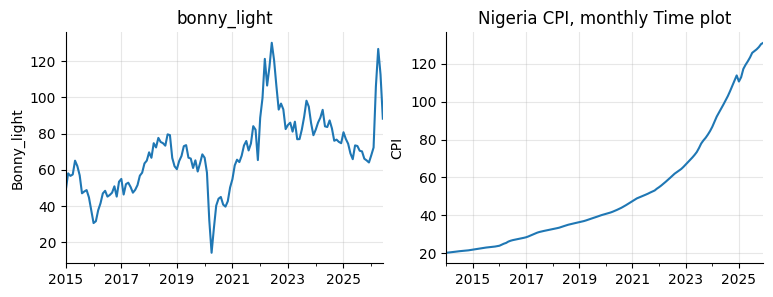

In [7]:
# time plot
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
bonny.plot(ax=axes[0], title='bonny_light', ylabel= 'Bonny_light', xlabel= 'Year')
cpi.plot(ax=axes[1], title='Nigeria CPI, monthly Time plot', ylabel='CPI', xlabel='Year')
for ax in axes.flat: ax.set_xlabel('')

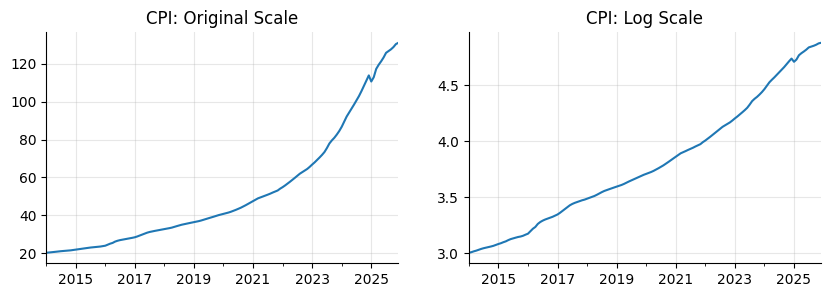

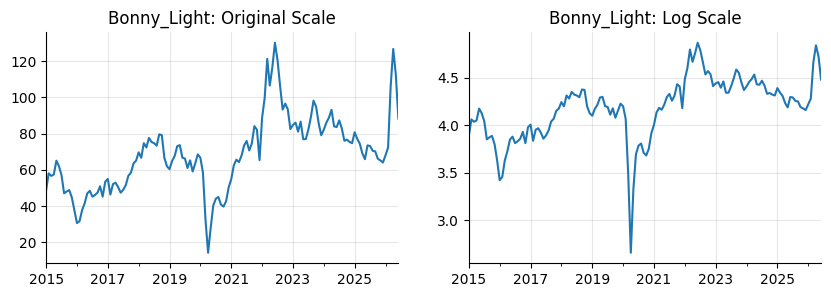

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
cpi.plot(ax=axes[0], title='CPI: Original Scale')
np.log(cpi).plot(ax=axes[1], title='CPI: Log Scale')
for ax in axes: ax.set_xlabel('')

print()
print()
print()

fig, axes = plt.subplots(1, 2, figsize=(10, 3))
bonny.plot(ax=axes[0], title='Bonny_Light: Original Scale')
np.log(bonny).plot(ax=axes[1], title='Bonny_Light: Log Scale')
for ax in axes: ax.set_xlabel('')

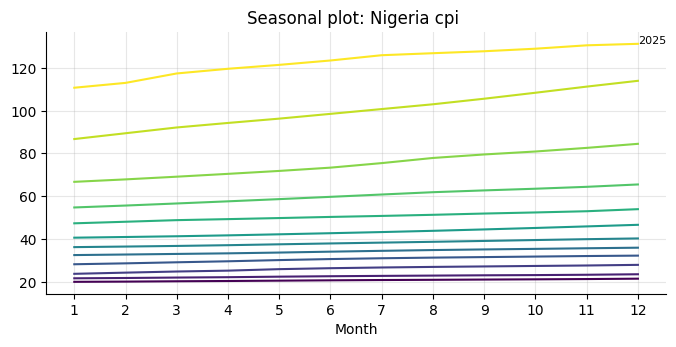

In [14]:
# Seasonal Plot for Nigeria CPI
def seasonal_plot(s, period_label='year', title=''):
    df = pd.DataFrame({'v': s.values, 'year': s.index.year, 'month': s.index.month})
    piv = df.pivot(index='month', columns='year', values='v')
    ax = piv.plot(legend=False, colormap='viridis', title=title, figsize=(8, 3.4))
    ax.set_xlabel('Month'); ax.set_xticks(range(1, 13))
    for col in piv.columns[-1:]: ax.annotate(str(col), (12, piv[col].iloc[-1]), fontsize=8)
    return ax
seasonal_plot(cpi, title='Seasonal plot: Nigeria cpi ')
plt.show()

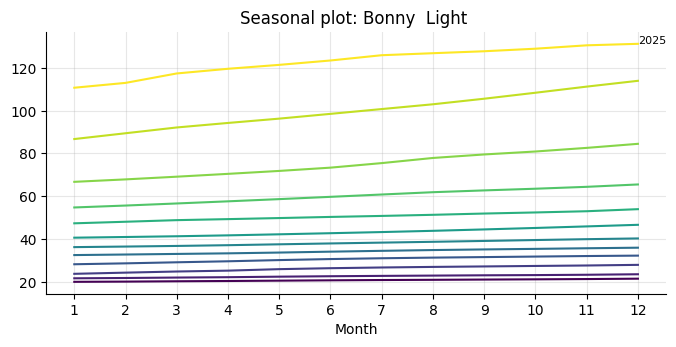

In [15]:
# Seasonal Plot for Bonny Light
def seasonal_plot(s, period_label='year', title=''):
    df = pd.DataFrame({'v': s.values, 'year': s.index.year, 'month': s.index.month})
    piv = df.pivot(index='month', columns='year', values='v')
    ax = piv.plot(legend=False, colormap='viridis', title=title, figsize=(8, 3.4))
    ax.set_xlabel('Month'); ax.set_xticks(range(1, 13))
    for col in piv.columns[-1:]: ax.annotate(str(col), (12, piv[col].iloc[-1]), fontsize=8)
    return ax
seasonal_plot(cpi, title='Seasonal plot: Bonny  Light ')
plt.show()

Commentary:

## 2. Methods considered and rejected

*benchmark; decomposition-based; ARIMA; SARIMA; regression with ARIMA errors*

In [ ]:
# code


Commentary:

## 3. Evaluation on the last 12 months against naive

*MAE / MASE; coverage*

In [ ]:
# code


Commentary:

## 4. Twelve-month forecast with 80% and 95% ranges, converted to year-on-year

*state every assumption, including the rebasing splice*

In [ ]:
# code


Commentary:

## 5. The budget assumption and the asymmetry of consequences

*point, conservative upper value, or other: justify*

In [ ]:
# code


Commentary:

## 6. Risks and indicators to monitor

*what would make the forecast wrong*

In [ ]:
# code


Commentary:

## AI-use statement

(Two to five lines: which tools, for what. 'No AI tools were used' is acceptable.)